In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# Configure presentation aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)

# Resolve paths
home_directory = Path.home()
data_directory = home_directory / "Documents/1_Projects/capstone/cap_proving_gnd/data-analysis/csv"

# Load Telemetry CSVs
telemetry_tx = pd.read_csv(data_directory / "wban_sim_tx.csv")
telemetry_rx = pd.read_csv(data_directory / "wban_sim_lpu_rx.csv")
telemetry_hub = pd.read_csv(data_directory / "wban_sim_hub.csv")
telemetry_drops = pd.read_csv(data_directory / "wban_sim_drops.csv")
telemetry_queues = pd.read_csv(data_directory / "wban_sim_queues.csv")

# Standardize Priority Tags
priority_mapping = {0: 'CP (Priority 0)', 1: 'RP (Priority 1)', 2: 'OP (Priority 2)'}
for dataframe in [telemetry_tx, telemetry_rx, telemetry_drops, telemetry_hub]:
    if 'Priority' in dataframe.columns and not dataframe.empty:
        dataframe['Quality_Of_Service_Tag'] = dataframe['Priority'].map(priority_mapping)

# Map Node IDs to Sensor Profiles
sensor_metadata = {
    2: {"SensorName": "EEG", "SensorType": "Streaming (P0)"},
    3: {"SensorName": "Respiration", "SensorType": "Streaming (P0)"}, 
    5: {"SensorName": "ECG", "SensorType": "Streaming (P0)"},
    10: {"SensorName": "EMG", "SensorType": "Streaming (P0)"},
    6: {"SensorName": "BloodPressure", "SensorType": "High Event (P1)"},
    7: {"SensorName": "GlucoseMonitor", "SensorType": "High Event (P1)"},
    8: {"SensorName": "SpO2", "SensorType": "High Event (P1)"},
    4: {"SensorName": "Temperature", "SensorType": "Routine (P2)"},
    9: {"SensorName": "Accelerometer", "SensorType": "Routine (P2)"},
    11: {"SensorName": "MotionSensor", "SensorType": "Routine (P2)"}
}

# Precalculate Microsecond Delays
telemetry_rx = telemetry_rx.sort_values(by=['NodeID', 'Time_s'])
telemetry_rx['End_To_End_Delay_Microseconds'] = telemetry_rx['E2EDelay_s'] * 1_000_000
telemetry_rx['Jitter_Microseconds'] = telemetry_rx.groupby('NodeID')['End_To_End_Delay_Microseconds'].diff().abs()

# Precalculate Interval Deltas for Queues
for queue_type in ['CP', 'RP', 'OP']:
    telemetry_queues[f'{queue_type}_Drops_Interval'] = telemetry_queues[f'{queue_type}_Drops'].diff().fillna(0)
    telemetry_queues[f'{queue_type}_Delay_Interval'] = telemetry_queues[f'{queue_type}_Delay'].diff().fillna(0)
    telemetry_queues[f'{queue_type}_Arrivals_Interval'] = telemetry_queues[f'{queue_type}_Arrivals'].diff().fillna(0)

print(f"Data successfully loaded. Processed {len(telemetry_rx)} received packets.")

Data successfully loaded. Processed 6162 received packets.


In [4]:
print("--- STAGE-BY-STAGE NETWORK METRICS ---")

application_layer_drops = len(telemetry_drops[telemetry_drops['Layer'] == 'APP'])
total_sensor_transmissions = len(telemetry_tx)
total_packets_generated = total_sensor_transmissions + application_layer_drops

hub_received_dataframe = telemetry_hub[telemetry_hub['Event'] == 'Rx_802.15.4']
total_hub_received = len(hub_received_dataframe)
total_lpu_received = len(telemetry_rx)

tier_1_delivery_ratio = (total_hub_received / total_packets_generated) * 100
overall_delivery_ratio = (total_lpu_received / total_packets_generated) * 100

print(f"Total Packets Generated:                     {total_packets_generated:,}")
print(f"Packets Reached Coordinator (Tier-1):        {total_hub_received:,} ({tier_1_delivery_ratio:.2f}%)")
print(f"Packets Reached Sink (Overall Delivery):     {total_lpu_received:,} ({overall_delivery_ratio:.2f}%)")

print("\n--- MEAN DELAY & JITTER BY PRIORITY ---")
delay_summary = telemetry_rx.groupby('Quality_Of_Service_Tag')[['End_To_End_Delay_Microseconds', 'Jitter_Microseconds']].mean().round(2)
display(delay_summary)

simulation_duration_seconds = 300.0 
total_bytes_received = telemetry_rx['Size_bytes'].sum()
network_goodput_bps = (total_bytes_received * 8) / simulation_duration_seconds

print(f"\nOverall Application Goodput: {network_goodput_bps:.2f} bps")

--- STAGE-BY-STAGE NETWORK METRICS ---
Total Packets Generated:                     6,314
Packets Reached Coordinator (Tier-1):        6,330 (100.25%)
Packets Reached Sink (Overall Delivery):     6,162 (97.59%)

--- MEAN DELAY & JITTER BY PRIORITY ---


,End_To_End_Delay_Microseconds,Jitter_Microseconds
Quality_Of_Service_Tag,,
CP (Priority 0),58589.34,97379.59
OP (Priority 2),251792.01,223142.54
RP (Priority 1),158986.98,145165.95



Overall Application Goodput: 11645.92 bps


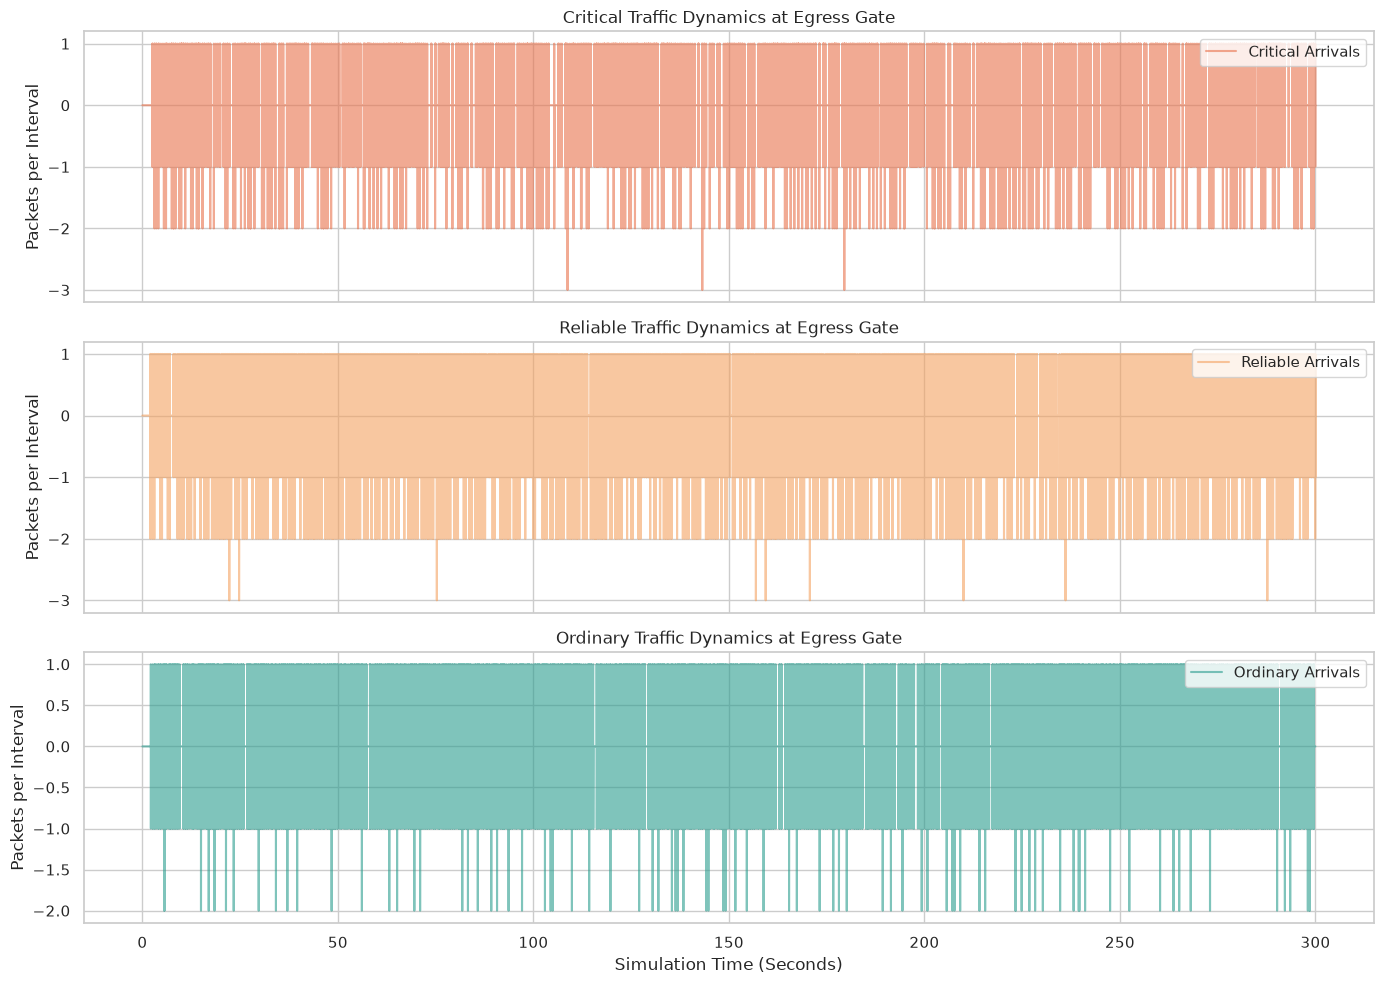

In [5]:
figure, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
queue_colors = {'CP': '#E9724C', 'RP': '#F4A261', 'OP': '#2A9D8F'}
queue_labels = {'CP': 'Critical', 'RP': 'Reliable', 'OP': 'Ordinary'}

for index, queue_type in enumerate(['CP', 'RP', 'OP']):
    label = queue_labels[queue_type]
    color = queue_colors[queue_type]
    
    arrivals = telemetry_queues[f'{queue_type}_Arrivals_Interval']
    axes[index].plot(telemetry_queues['Time_s'], arrivals, label=f'{label} Arrivals', color=color, alpha=0.6)
    
    total_interval_drops = telemetry_queues[f'{queue_type}_Drops_Interval'].sum()
    if total_interval_drops > 0:
        drops = telemetry_queues[f'{queue_type}_Drops_Interval']
        axes[index].bar(telemetry_queues['Time_s'], drops, width=0.05, label=f'{label} Drops', color='black', alpha=0.8)
        
    axes[index].set_ylabel('Packets per Interval')
    axes[index].legend(loc='upper right')
    axes[index].set_title(f'{label} Traffic Dynamics at Egress Gate')

axes[2].set_xlabel('Simulation Time (Seconds)')
plt.tight_layout()
plt.show()

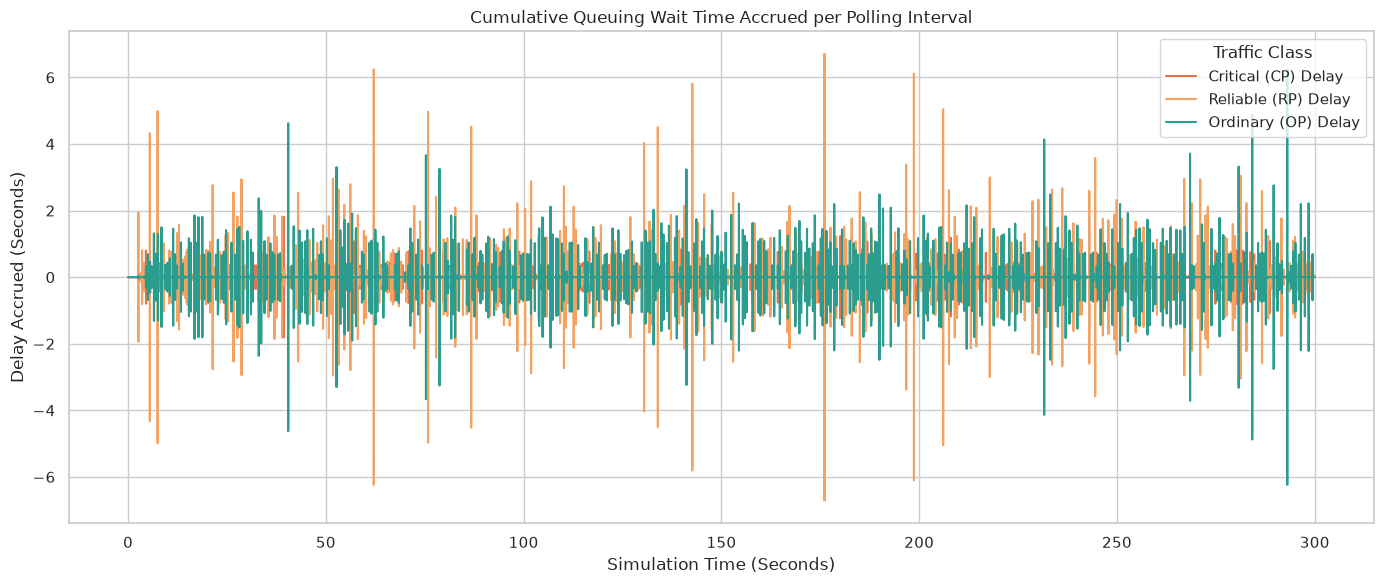

In [6]:
plt.figure(figsize=(14, 6))

sns.lineplot(data=telemetry_queues, x='Time_s', y='CP_Delay_Interval', label='Critical (CP) Delay', color='#E9724C', linewidth=1.5)
sns.lineplot(data=telemetry_queues, x='Time_s', y='RP_Delay_Interval', label='Reliable (RP) Delay', color='#F4A261', linewidth=1.5)
sns.lineplot(data=telemetry_queues, x='Time_s', y='OP_Delay_Interval', label='Ordinary (OP) Delay', color='#2A9D8F', linewidth=1.5)

plt.title('Cumulative Queuing Wait Time Accrued per Polling Interval')
plt.xlabel('Simulation Time (Seconds)')
plt.ylabel('Delay Accrued (Seconds)')
plt.legend(title='Traffic Class')
plt.tight_layout()
plt.show()

,Tier 1 (Sensor to Coord),Tier 2 (Coord to Sink)
Quality_Of_Service_Tag,,
CP (Priority 0),6.03,52.56
OP (Priority 2),3.42,248.36
RP (Priority 1),6.12,152.81


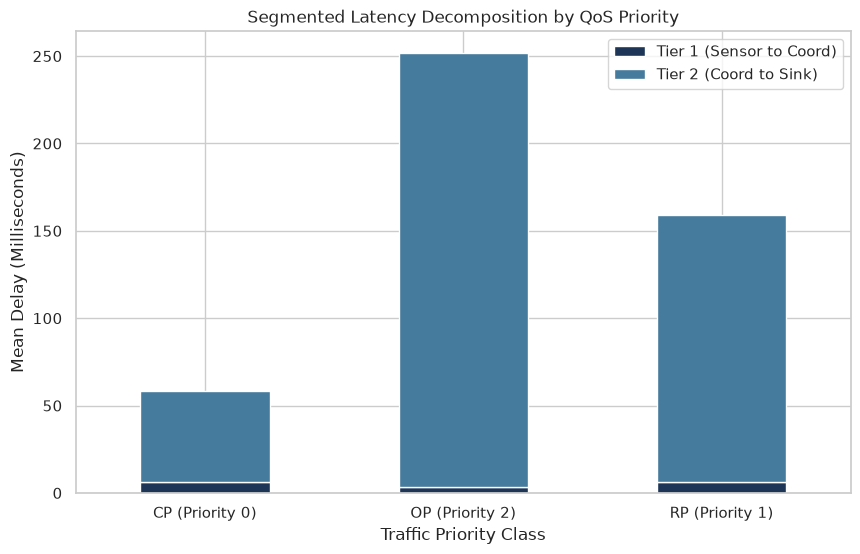

In [7]:
hub_received_subset = hub_received_dataframe[['NodeID', 'SeqNum', 'Time_s']].rename(
    columns={'Time_s': 'Time_s_Hub'}
)

# Merge tables to track the specific packet across both network tiers
lifecycle_dataframe = telemetry_tx.merge(
    hub_received_subset, on=['NodeID', 'SeqNum'], how='inner'
)
lifecycle_dataframe = lifecycle_dataframe.merge(
    telemetry_rx[['NodeID', 'SeqNum', 'Time_s']],
    on=['NodeID', 'SeqNum'],
    suffixes=('_Tx', '_Lpu')
)

lifecycle_dataframe['Tier_1_Delay_Milliseconds'] = (
    lifecycle_dataframe['Time_s_Hub'] - lifecycle_dataframe['Time_s_Tx']
) * 1_000

lifecycle_dataframe['Tier_2_Delay_Milliseconds'] = (
    lifecycle_dataframe['Time_s_Lpu'] - lifecycle_dataframe['Time_s_Hub']
) * 1_000

tier_1_mean_delay = lifecycle_dataframe.groupby('Quality_Of_Service_Tag')[
    'Tier_1_Delay_Milliseconds'
].mean()

tier_2_mean_delay = lifecycle_dataframe.groupby('Quality_Of_Service_Tag')[
    'Tier_2_Delay_Milliseconds'
].mean()

latency_decomposition = pd.DataFrame({
    'Tier 1 (Sensor to Coord)': tier_1_mean_delay,
    'Tier 2 (Coord to Sink)': tier_2_mean_delay
}).dropna(how='all')

display(latency_decomposition.round(2))

latency_decomposition.plot(
    kind='bar',
    stacked=True,
    color=['#1D3557', '#457B9D'],
    figsize=(10, 6)
)

plt.title('Segmented Latency Decomposition by QoS Priority')
plt.ylabel('Mean Delay (Milliseconds)')
plt.xlabel('Traffic Priority Class')
plt.xticks(rotation=0)
plt.show()